<a href="https://colab.research.google.com/github/aray-png/Problem-Set-2-Econ_5200_PS2.ipynb/blob/main/Copy_of_ps2_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS2 — The Underpowered Portfolio

**Abigail Ray || ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 5-8 · 100 points · your role: Experimentation lead, consulting engagement

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is experimentation lead's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: Reconstruct the Portfolio (30 pts)

### Step 1.1: Simulate the experiment programme (15 pts)

### The prior on true effects

Each experiment tests a change to a conversion rate with a 10% baseline. True effects, specific to percentage points come from a two-part mixture.

- with prpobability 0.75, null the effect ~ Normal(0, 0.001). These are changes that do essentially nothing and about 95% of them fall within ±0.2 pp of zero.
- but with a probability of 0.25 there is an effect ~ |Normal(0.008, 0.004)|, centred on +0.8 pp, always positive.

Overall, the prior puts roughly 75 percent of the effects near 0 and a minority of about 25% that are genuinely positive. Sample size per arm is drawn log-uniformly between 1k and 50k, so the portfolio mixes small, underpowered tests with large, well-powered ones.

In [2]:
exp_rng = np.random.default_rng(2026)
N_EXPERIMENTS = 200
BASELINE_RATE = 0.10
P_NULL = 0.75
NULL_SD = 0.001
POS_MEAN, POS_SD = 0.008, 0.004
N_MIN, N_MAX = 1_000, 50_000

is_real = exp_rng.random(N_EXPERIMENTS) > P_NULL
true_effect = np.where(is_real,
                       np.abs(exp_rng.normal(POS_MEAN, POS_SD, N_EXPERIMENTS)),
                       exp_rng.normal(0, NULL_SD, N_EXPERIMENTS))

#sample sizes
n_per_arm = np.round(np.exp(exp_rng.uniform(np.log(N_MIN), np.log(N_MAX), N_EXPERIMENTS))).astype(int)

#running each experiment
conv_control = exp_rng.binomial(n_per_arm, BASELINE_RATE)
conv_treat   = exp_rng.binomial(n_per_arm, BASELINE_RATE + true_effect)
rate_c = conv_control / n_per_arm
rate_t = conv_treat / n_per_arm

#the estimate and its standard error
estimate  = rate_t - rate_c
std_error = np.sqrt(rate_c * (1 - rate_c) / n_per_arm + rate_t * (1 - rate_t) / n_per_arm)

#power of each test to detect its own true effect
se_true = np.sqrt(2 * BASELINE_RATE * (1 - BASELINE_RATE) / n_per_arm)
power = (stats.norm.sf(1.96 - true_effect / se_true)
         + stats.norm.cdf(-1.96 - true_effect / se_true))

experiments = pd.DataFrame({
    "experiment_id": np.arange(1, N_EXPERIMENTS + 1),
    "n_per_arm":     n_per_arm,
    "true_effect":   true_effect,
    "is_real":       is_real,
    "estimate":      estimate,
    "std_error":     std_error,
    "z":             estimate / std_error,
    "power":         power,
})
display(experiments.head())

,experiment_id,n_per_arm,true_effect,is_real,estimate,std_error,z,power
0,1,14495,6.126e-04,False,2.622e-03,0.004,0.734,0.053
1,2,28983,1.331e-03,False,2.484e-03,0.002,1.001,0.083
2,3,10825,-2.166e-03,False,-5.543e-04,0.004,-0.137,0.083
3,4,5901,-1.649e-03,False,-1.118e-02,0.006,-2.006,0.060
4,5,22539,1.462e-03,False,7.986e-04,0.003,0.278,0.081


In [3]:
print(f"Prior: with prob {P_NULL:.2f}, effect ~ Normal(0, {NULL_SD})          (a null)")
print(f"       with prob {1 - P_NULL:.2f}, effect ~ |Normal({POS_MEAN}, {POS_SD})|  (a real lift)")
print(f"Baseline conversion {BASELINE_RATE:.0%}; n per arm log-uniform on [{N_MIN:,}, {N_MAX:,}]")
print()
print(f"Experiments: {N_EXPERIMENTS}; genuinely positive: {is_real.sum()} ({is_real.mean():.0%})")
print(f"Share of true effects within ±0.2 pp of zero: {(np.abs(true_effect) < 0.002).mean():.0%}")
print(f"n per arm: min {n_per_arm.min():,}, median {int(np.median(n_per_arm)):,}, max {n_per_arm.max():,}")
print(f"Power on the real effects: min {power[is_real].min():.0%}, "
      f"median {np.median(power[is_real]):.0%}, max {power[is_real].max():.0%}")

Prior: with prob 0.75, effect ~ Normal(0, 0.001)          (a null)
       with prob 0.25, effect ~ |Normal(0.008, 0.004)|  (a real lift)
Baseline conversion 10%; n per arm log-uniform on [1,000, 50,000]

Experiments: 200; genuinely positive: 43 (22%)
Share of true effects within ±0.2 pp of zero: 76%
n per arm: min 1,006, median 10,886, max 49,958
Power on the real effects: min 5%, median 31%, max 100%


*Your answer here.*

The median real effect has only a 31% chance of being detected, while the largest tests catch their effects almost every time. Each experiment is actually run. Drawing conversions from a binomial gives realistic noise, and the standard error is computed from the observed rates, as an analyst would.
true_effect and is_real are kept in the table, so later steps can check every decision against the truth. It uses its own generator so earlier cells can’t change these numbers.

### Step 1.2: Apply the client's rule (15 pts)

In [4]:
#two-sided p-value for each experiment
experiments["p_value"] = 2 * stats.norm.sf(np.abs(experiments["z"]))
experiments["ships"] = (experiments["p_value"] < 0.05) & (experiments["estimate"] > 0)
shipped = experiments[experiments["ships"]]

n_ship        = len(shipped)
share_null    = (~shipped["is_real"]).mean()
avg_estimated = shipped["estimate"].mean()

print(f"Experiments shipped:                       {n_ship} of {N_EXPERIMENTS}")
print(f"Shipped with a true effect of ~zero:       {(~shipped['is_real']).sum()} ({share_null:.0%})")
print(f"Average TRUE effect among shipped:         {avg_true * 100:+.2f} pp")
print(f"Average ESTIMATED effect among shipped:    {avg_estimated * 100:+.2f} pp")
print(f"Estimated / true:                          {avg_estimated / avg_true:.2f}x")

Experiments shipped:                       23 of 200
Shipped with a true effect of ~zero:       4 (17%)
Average TRUE effect among shipped:         +0.75 pp
Average ESTIMATED effect among shipped:    +1.21 pp
Estimated / true:                          1.60x


The rule ships 23 of 200 experiments. 4 of them (17%) had a true effect of essentially zero and they were nulls that cleared p < 0.05 by luck. Among shipped experiments, the average estimated lift is +1.21 pp, but the average true lift is only +0.75 pp. The reported wins overstate the real gain by about 60%.  Shipping only significant results selects the experiments whose noise happened to push the estimate up. That matters most in small, underpowered tests becuase a modest true effect only clears the bar when random error inflates it. So the act of filtering on p < 0.05 guarantees that the estimates you ship are biased upward.

## Phase 2: The Winner's Curse (35 pts)

### Step 2.1: Quantify the exaggeration (20 pts)

In [5]:
se_design = np.sqrt(2 * BASELINE_RATE * (1 - BASELINE_RATE) / experiments["n_per_arm"])
experiments["design_power"] = (stats.norm.sf(1.96 - POS_MEAN / se_design)
                               + stats.norm.cdf(-1.96 - POS_MEAN / se_design))

POWER_CUTS = [0, 0.3, 0.8, 1.01]
experiments["power_band"] = pd.cut(experiments["design_power"], POWER_CUTS,
                                   labels=["low", "medium", "high"], right=False)

#1.96 standard errors
experiments["ship_bar_pp"] = 1.96 * se_design * 100

shipped = experiments[experiments["ships"]]
overall_inflation = shipped["estimate"].mean() / shipped["true_effect"].mean()
print(f"Average inflation factor, all shipped: {overall_inflation:.2f}x  "
      f"(mean estimate / mean true effect)")

by_power = shipped.groupby("power_band", observed=False).agg(
    shipped=("ships", "size"),
    nulls_shipped=("is_real", lambda x: (~x).sum()),
    avg_true_pp=("true_effect", lambda x: x.mean() * 100),
    avg_estimate_pp=("estimate", lambda x: x.mean() * 100),
)
by_power.insert(0, "experiments", experiments.groupby("power_band", observed=False).size())
by_power.insert(1, "median_ship_bar_pp",
                experiments.groupby("power_band", observed=False)["ship_bar_pp"].median())
by_power["inflation"] = by_power["avg_estimate_pp"] / by_power["avg_true_pp"]
display(by_power.round(2))

Average inflation factor, all shipped: 1.60x  (mean estimate / mean true effect)


,experiments,median_ship_bar_pp,shipped,nulls_shipped,avg_true_pp,avg_estimate_pp,inflation
power_band,,,,,,,
low,65,1.61,5,0,0.92,2.18,2.38
medium,77,0.76,6,0,0.87,1.24,1.43
high,58,0.44,12,4,0.63,0.78,1.24


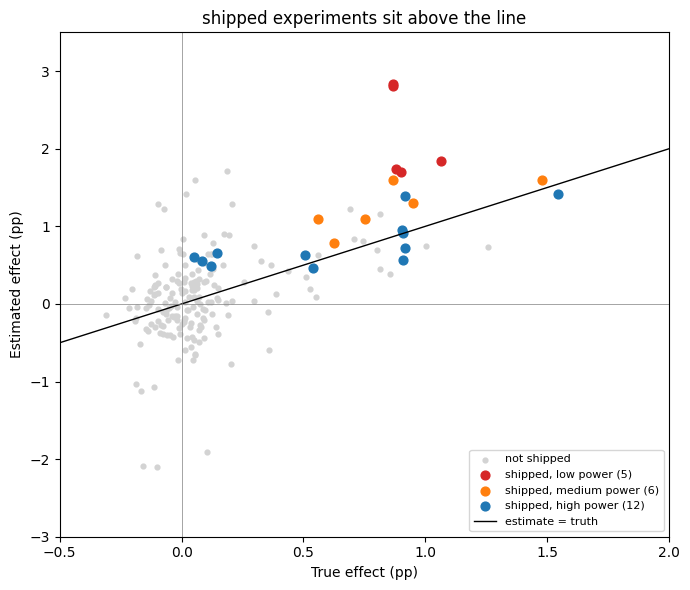

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))
not_shipped = experiments[~experiments["ships"]]
ax.scatter(not_shipped["true_effect"] * 100, not_shipped["estimate"] * 100,
           s=12, color="lightgrey", label="not shipped")

colors = {"low": "#d62728", "medium": "#ff7f0e", "high": "#1f77b4"}
for band, color in colors.items():
    s = shipped[shipped["power_band"] == band]
    ax.scatter(s["true_effect"] * 100, s["estimate"] * 100, s=40, color=color,
               label=f"shipped, {band} power ({len(s)})")

ax.plot([-1, 3.5], [-1, 3.5], color="black", lw=1, label="estimate = truth")
ax.axvline(0, color="grey", lw=0.5)
ax.axhline(0, color="grey", lw=0.5)
ax.set_xlim(-0.5, 2.0)
ax.set_ylim(-3, 3.5)
ax.set_xlabel("True effect (pp)")
ax.set_ylabel("Estimated effect (pp)")
ax.set_title("shipped experiments sit above the line")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

*Your answer here.*

An experiment's estimate is its true effect plus noise, and the noise is as likely to push it up as down. But an experiment only ships when its estimate clears the significance bar, about 1.96 standard errors. Each estimate was unbiased before filtered, but the shipped set is selected on having overestimated, which is why the average shipped estimate is 1.60× the average true effect.

Power is about how high the bar sits relative to the true effect. In a low-powered test the bar is about 1.6 pp, while the real lifts in the portfolio are around 0.8–0.9 pp. A real effect can only clear that bar if noise adds roughly as much again on top of it, so every low-powered test that ships does so because its noise was large and positive. In a high-powered test the bar is only about 0.4 pp, below most real effects, so a real lift clears it with little or no help from noise and the estimate stays close to the truth. Simply put, the less power a test has, the more upward noise it needs to ship, and that extra noise is exactly the exaggeration.

### Step 2.2: The bootstrap where the formula fails (15 pts)

In [7]:
contrib = (experiments["true_effect"] * experiments["ships"]).to_numpy()
realised_return = contrib.sum()
claimed_return = (experiments["estimate"] * experiments["ships"]).sum()

boot_rng = np.random.default_rng(7)
B = 10_000
n = len(contrib)

boot_sums = np.empty(B)
for b in range(B):
    idx = boot_rng.integers(0, n, n)
    boot_sums[b] = contrib[idx].sum()

loop_se = boot_sums.std(ddof=1)
loop_ci = np.percentile(boot_sums, [2.5, 97.5])

print(f"Realised return (sum of true effects, shipped): {realised_return * 100:+.2f} pp "
      f"over {experiments['ships'].sum()} experiments")
print(f"Claimed return (sum of estimates, shipped):     {claimed_return * 100:+.2f} pp")
print()
print(f"My loop:  SE {loop_se * 100:.2f} pp   percentile 95% CI "
      f"[{loop_ci[0] * 100:+.2f}, {loop_ci[1] * 100:+.2f}] pp")

Realised return (sum of true effects, shipped): +17.35 pp over 23 experiments
Claimed return (sum of estimates, shipped):     +27.74 pp

My loop:  SE 3.86 pp   percentile 95% CI [+10.11, +25.15] pp


scipy:    SE 3.86 pp   percentile 95% CI [+10.08, +25.11] pp
scipy:    BCa 95% CI [+10.80, +26.30] pp

Experiments contributing a non-zero amount: 23 of 200
Largest single contribution: 1.54 pp (9% of the total)
Skewness of the bootstrap distribution: 0.21
Distinct bootstrap values: 10,000 of 10,000


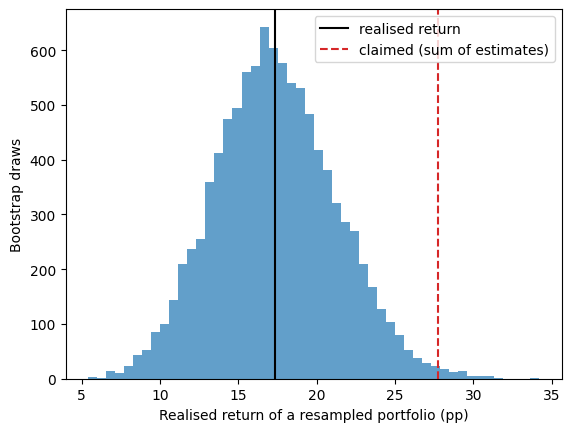

In [8]:
def total(x, axis):
    return np.sum(x, axis=axis)

res_pct = stats.bootstrap((contrib,), total, n_resamples=B, method="percentile",
                          random_state=np.random.default_rng(8))
res_bca = stats.bootstrap((contrib,), total, n_resamples=B, method="BCa",
                          random_state=np.random.default_rng(8))

print(f"scipy:    SE {res_pct.standard_error * 100:.2f} pp   percentile 95% CI "
      f"[{res_pct.confidence_interval.low * 100:+.2f}, {res_pct.confidence_interval.high * 100:+.2f}] pp")
print(f"scipy:    BCa 95% CI [{res_bca.confidence_interval.low * 100:+.2f}, "
      f"{res_bca.confidence_interval.high * 100:+.2f}] pp")
print()
print(f"Experiments contributing a non-zero amount: {(contrib != 0).sum()} of {n}")
print(f"Largest single contribution: {contrib.max() * 100:.2f} pp "
      f"({contrib.max() / realised_return:.0%} of the total)")
print(f"Skewness of the bootstrap distribution: {stats.skew(boot_sums):.2f}")
print(f"Distinct bootstrap values: {len(np.unique(boot_sums)):,} of {B:,}")

plt.hist(boot_sums * 100, bins=50, color="#1f77b4", alpha=0.7)
plt.axvline(realised_return * 100, color="black", lw=1.5, label="realised return")
plt.axvline(claimed_return * 100, color="#d62728", lw=1.5, ls="--", label="claimed (sum of estimates)")
plt.xlabel("Realised return of a resampled portfolio (pp)")
plt.ylabel("Bootstrap draws")
plt.legend()
plt.show()

*Your answer here.*

The portfolio's realised return is +17.4 pp, with a bootstrap SE of 3.9 pp and a 95% BCa interval of +10.8 to +26.3 pp. The +27.7 pp the team would report by adding up its shipped estimates lies outside the interval. The bootstrap distribution is mildly right-skewed, because most experiments contribute 0 and a few contribute about 1 pp. BCa corrects for that skew, and for any bias in the bootstrap distribution, which is why its interval sits slightly to the right of the percentile one.

Failure modes I checked before trusting it fully,
1. The bootstrap breaks for statistics like a maximum or an extreme quantile. This one is a sum of per-experiment contributions, which is smooth, and the shipping rule depends only on each experiment's own data, not on a ranking across experiments.
2. Only 23 of 200 experiments contribute, which is the real risk here. But the bootstrap distribution has 10,000 distinct values and no lumps, and no single experiment dominates.
3. Resampling individual rows assumes experiments are independent, which holds by construction here. In a real programme, tests that share traffic or run in the same season would need a block bootstrap.
4. Contributions are bounded, so there are no extreme values to destabilise the resampled sums.

## Phase 3: A Rule They Can Adopt (25 pts)

### Step 3.1: Design the alternative (20 pts)

In [9]:
est = experiments["estimate"].to_numpy()
se  = experiments["std_error"].to_numpy()
like_null = stats.norm.pdf(est, 0,        np.sqrt(NULL_SD**2 + se**2))
like_real = stats.norm.pdf(est, POS_MEAN, np.sqrt(POS_SD**2  + se**2))
p_real = (1 - P_NULL) * like_real / ((1 - P_NULL) * like_real + P_NULL * like_null)

w_real = POS_SD**2  / (POS_SD**2  + se**2)
w_null = NULL_SD**2 / (NULL_SD**2 + se**2)
mean_if_real = POS_MEAN + w_real * (est - POS_MEAN)
mean_if_null = w_null * est

experiments["shrunk"] = p_real * mean_if_real + (1 - p_real) * mean_if_null

HURDLE = 0.003
rules = {
    "Client: p < .05":                 experiments["ships"],
    "Stricter: p < .01":               (experiments["p_value"] < 0.01) & (experiments["estimate"] > 0),
    "Power floor 80%, then p < .05":   (experiments["design_power"] >= 0.8) & experiments["ships"],
    "Mine: shrunk estimate > 0.3 pp":  experiments["shrunk"] > HURDLE,
}

rows = []
for name, ship in rules.items():
    s = experiments[ship]
    rows.append({
        "rule": name,
        "shipped": int(ship.sum()),
        "real wins shipped": int(s["is_real"].sum()),
        "false-ship rate": (~s["is_real"]).mean(),
        "realised return (pp)": s["true_effect"].sum() * 100,
        "forecast return (pp)": (s["shrunk"] if name.startswith("Mine") else s["estimate"]).sum() * 100,
    })
comparison = pd.DataFrame(rows).set_index("rule")
display(comparison.style.format({"false-ship rate": "{:.0%}", "realised return (pp)": "{:.1f}",
                                 "forecast return (pp)": "{:.1f}"}))

,shipped,real wins shipped,false-ship rate,realised return (pp),forecast return (pp)
rule,,,,,
Client: p < .05,23,19,17%,17.4,27.7
Stricter: p < .01,12,11,8%,11.3,15.2
"Power floor 80%, then p < .05",12,8,33%,7.5,9.3
Mine: shrunk estimate > 0.3 pp,36,26,28%,22.7,23.2


*Your answer here.*

My rule was to shrink every estimate toward the prior, then ship if the shrunken estimate exceeds 0.3 pp. On the same 200 experiments it realises +22.7 pp against the client's +17.4 pp, shipping 36 changes instead of 23 and catching 26 of the 43 real lifts instead of 19. However, the false-ship rate rises from 17% to 28%. Under the client's objective that costs almost nothing, because a null's true effect is essentially zero, so shipping one neither adds nor subtracts much. The extra real lifts more than pay for it.
The client's rule promises +27.7 pp and delivers +17.4 pp. Mine promises +23.2 pp and delivers +22.7 pp, because shrinkage removes the upward bias before the number reaches the CFO.

The strickter rule fails because both p < .01 and the power floor cut false ships in the threshold case, but they lose on realised return because they throw away real but modest lifts. The power floor is worst because it bans 142 of 200 experiments from shipping at all, and so discards most of the portfolio's real lifts.

### Step 3.2: Ship the module (5 pts, its own rubric row)

The module the brief asks for. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [10]:
%%writefile src/experiment_portfolio.py
"""Experiment-portfolio simulator and decision rules (ECON 5200 PS2).

Every experiment in the log carries its true effect, so any shipping rule can be scored
on what it actually delivered rather than on what its estimates promised.
"""
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
import pandas as pd
from scipy import stats

Z_975 = stats.norm.ppf(0.975)


@dataclass(frozen=True)
class Prior:
    """Mixture prior on true effects (in conversion-rate units: 0.01 = 1 pp)."""
    p_null: float = 0.75        # share of experiments with no real effect
    null_sd: float = 0.001      # nulls ~ Normal(0, null_sd)
    pos_mean: float = 0.008     # real lifts ~ |Normal(pos_mean, pos_sd)|
    pos_sd: float = 0.004


@dataclass(frozen=True)
class Rule:
    """A shipping rule.

    kind = "threshold":   ship if p < alpha and the estimate is positive.
    kind = "power_floor": as "threshold", but only tests with design power >= min_power may ship.
    kind = "shrinkage":   ship if the estimate, shrunk toward the prior, exceeds `hurdle`.
    """
    kind: str = "threshold"
    alpha: float = 0.05
    min_power: float = 0.8
    hurdle: float = 0.003


def simulate_portfolio(n: int, seed: int, **kwargs) -> pd.DataFrame:
    """Return the experiment log with the true effect attached.

    Simulates `n` two-arm conversion experiments. Optional keyword arguments:
    prior (Prior), baseline_rate (default 0.10), n_min and n_max (sample size per arm,
    drawn log-uniformly; defaults 1,000 and 50,000).

    Columns: experiment_id, n_per_arm, true_effect, is_real, estimate, std_error, z,
    p_value, design_power. The prior and baseline are stored in `log.attrs`.
    """
    prior: Prior = kwargs.get("prior", Prior())
    baseline_rate: float = kwargs.get("baseline_rate", 0.10)
    n_min: int = kwargs.get("n_min", 1_000)
    n_max: int = kwargs.get("n_max", 50_000)

    rng = np.random.default_rng(seed)
    is_real = rng.random(n) > prior.p_null
    true_effect = np.where(is_real,
                           np.abs(rng.normal(prior.pos_mean, prior.pos_sd, n)),
                           rng.normal(0, prior.null_sd, n))
    n_per_arm = np.round(np.exp(rng.uniform(np.log(n_min), np.log(n_max), n))).astype(int)

    rate_c = rng.binomial(n_per_arm, baseline_rate) / n_per_arm
    rate_t = rng.binomial(n_per_arm, baseline_rate + true_effect) / n_per_arm
    estimate = rate_t - rate_c
    std_error = np.sqrt(rate_c * (1 - rate_c) / n_per_arm + rate_t * (1 - rate_t) / n_per_arm)
    z = estimate / std_error
    se_design = np.sqrt(2 * baseline_rate * (1 - baseline_rate) / n_per_arm)
    design_power = (stats.norm.sf(Z_975 - prior.pos_mean / se_design)
                    + stats.norm.cdf(-Z_975 - prior.pos_mean / se_design))

    log = pd.DataFrame({
        "experiment_id": np.arange(1, n + 1),
        "n_per_arm": n_per_arm,
        "true_effect": true_effect,
        "is_real": is_real,
        "estimate": estimate,
        "std_error": std_error,
        "z": z,
        "p_value": 2 * stats.norm.sf(np.abs(z)),
        "design_power": design_power,
    })
    log.attrs["prior"] = prior
    log.attrs["baseline_rate"] = baseline_rate
    return log


def shrunk_estimate(log: pd.DataFrame, prior: Prior | None = None) -> pd.Series:
    """Posterior mean of each true effect under the mixture prior (pulls noisy estimates toward 0)."""
    prior = prior or log.attrs.get("prior", Prior())
    est, se = log["estimate"].to_numpy(), log["std_error"].to_numpy()
    like_null = stats.norm.pdf(est, 0, np.sqrt(prior.null_sd**2 + se**2))
    like_real = stats.norm.pdf(est, prior.pos_mean, np.sqrt(prior.pos_sd**2 + se**2))
    p_real = (1 - prior.p_null) * like_real / ((1 - prior.p_null) * like_real
                                               + prior.p_null * like_null)
    w_real = prior.pos_sd**2 / (prior.pos_sd**2 + se**2)
    w_null = prior.null_sd**2 / (prior.null_sd**2 + se**2)
    mean_if_real = prior.pos_mean + w_real * (est - prior.pos_mean)
    mean_if_null = w_null * est
    return pd.Series(p_real * mean_if_real + (1 - p_real) * mean_if_null, index=log.index)


def apply_rule(log: pd.DataFrame, rule: Rule | str) -> pd.Series:
    """Ship decisions under `rule`: the p < 0.05 threshold and at least one other.

    `rule` is a Rule, or one of the names "threshold", "power_floor", "shrinkage"
    (which uses that rule's default settings). Returns a boolean Series, True = ships.
    """
    rule = Rule(rule) if isinstance(rule, str) else rule
    significant = (log["p_value"] < rule.alpha) & (log["estimate"] > 0)
    if rule.kind == "threshold":
        return significant
    if rule.kind == "power_floor":
        return significant & (log["design_power"] >= rule.min_power)
    if rule.kind == "shrinkage":
        return shrunk_estimate(log) > rule.hurdle
    raise ValueError(f"Unknown rule kind: {rule.kind!r}")


def evaluate(log: pd.DataFrame, rule: Rule | str) -> dict[str, float]:
    """Realised true return, ship count and false-ship rate under `rule`.

    Returns realised_return (sum of true effects shipped), claimed_return (what the rule's
    own estimates promised: raw estimates, or shrunk ones for the shrinkage rule),
    n_shipped and false_ship_rate (share of shipped that were nulls).
    """
    rule = Rule(rule) if isinstance(rule, str) else rule
    ship = apply_rule(log, rule)
    shipped = log[ship]
    claimed = shrunk_estimate(log)[ship] if rule.kind == "shrinkage" else shipped["estimate"]
    return {
        "realised_return": float(shipped["true_effect"].sum()),
        "claimed_return": float(claimed.sum()),
        "n_shipped": int(ship.sum()),
        "false_ship_rate": float((~shipped["is_real"]).mean()) if len(shipped) else 0.0,
    }


if __name__ == "__main__":
    log = simulate_portfolio(n=200, seed=2026)
    rules = {
        "threshold p<.05": Rule("threshold", alpha=0.05),
        "threshold p<.01": Rule("threshold", alpha=0.01),
        "power floor 80%": Rule("power_floor", alpha=0.05, min_power=0.8),
        "shrinkage >0.3pp": Rule("shrinkage", hurdle=0.003),
    }
    results = {name: evaluate(log, r) for name, r in rules.items()}
    for name, res in results.items():
        print(f"{name:<18} shipped {res['n_shipped']:>3}   realised {res['realised_return'] * 100:+6.2f} pp"
              f"   claimed {res['claimed_return'] * 100:+6.2f} pp   false-ship {res['false_ship_rate']:.0%}")
    assert {"true_effect", "is_real"} <= set(log.columns), "the log must carry the truth"
    loose, strict = apply_rule(log, rules["threshold p<.05"]), apply_rule(log, rules["threshold p<.01"])
    assert (strict <= loose).all(), "everything p<.01 ships must also ship under p<.05"
    assert (apply_rule(log, rules["power floor 80%"]) <= loose).all(), "a power floor can only remove ships"
    for res in results.values():
        assert 0.0 <= res["false_ship_rate"] <= 1.0, "false-ship rate is a share"
        assert res["realised_return"] <= log["true_effect"].clip(lower=0).sum() + 1e-12, \
            "no rule can realise more than the sum of all positive true effects"
    assert simulate_portfolio(50, seed=1).equals(simulate_portfolio(50, seed=1)), "seeded runs must reproduce"
    print("All assertions passed.")

Writing src/experiment_portfolio.py


In [11]:
import os, sys
import importlib
sys.path.insert(0, os.path.abspath('.'))
from src import experiment_portfolio as ep
importlib.reload(ep)

#calling the three functions on a small portfolio
small = ep.simulate_portfolio(n=50, seed=1)
print(f"Log: {small.shape[0]} experiments, columns {list(small.columns)}")
assert {"true_effect", "is_real"} <= set(small.columns)

for rule in ["threshold", "power_floor", "shrinkage"]:
    ships = ep.apply_rule(small, rule)
    res = ep.evaluate(small, rule)
    print(f"{rule:<12} ships {res['n_shipped']:>2}   realised {res['realised_return'] * 100:+.2f} pp"
          f"   false-ship {res['false_ship_rate']:.0%}")
    assert res["n_shipped"] == ships.sum()

Log: 50 experiments, columns ['experiment_id', 'n_per_arm', 'true_effect', 'is_real', 'estimate', 'std_error', 'z', 'p_value', 'design_power']
threshold    ships  3   realised +3.14 pp   false-ship 0%
power_floor  ships  1   realised +1.09 pp   false-ship 0%
shrinkage    ships 12   realised +6.68 pp   false-ship 42%


## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 7 for the AI row, 3 for the CFO memo)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The sequential design

In [12]:
## Version One output.
%%writefile src/sequential.py
"""Always-valid sequential testing for two-arm conversion experiments (mSPRT).

Uses the mixture sequential probability ratio test of Johari, Pekelis & Walsh (2017):
place a Normal(0, tau^2) mixing prior on the treatment effect, and reject H0: effect = 0
the first time the mixture likelihood ratio reaches 1/alpha. By Ville's inequality the
probability that a null stream EVER crosses that line is at most alpha, no matter how
often you look or when you stop.
"""
from __future__ import annotations

import numpy as np
from scipy import stats


def msprt_statistic(diff: np.ndarray, n: np.ndarray, var_pair: np.ndarray,
                    tau: float) -> np.ndarray:
    """Mixture likelihood ratio Lambda_n for a difference in means.

    diff:     running estimate of (treatment - control) at each look
    n:        observations per arm at each look
    var_pair: variance of one (treatment - control) pair, p_t(1-p_t) + p_c(1-p_c)
    tau:      SD of the Normal mixing prior on the effect (same units as diff)
    """
    V = var_pair / n                                   # variance of diff at this look
    return np.sqrt(V / (V + tau**2)) * np.exp(tau**2 * diff**2 / (2 * V * (V + tau**2)))


def sequential_decisions(control: np.ndarray, treatment: np.ndarray, alpha: float = 0.05,
                         tau: float = 0.008, look_every: int = 500,
                         burn_in: int = 500) -> dict[str, np.ndarray]:
    """Stopping decision at each look for one stream of paired 0/1 observations.

    control, treatment: equal-length arrays of conversions (0/1), in arrival order.
    Looks happen every `look_every` observations per arm, starting at `burn_in`.

    Returns arrays aligned to the looks:
      n          observations per arm at the look
      estimate   running difference in conversion rates
      msprt      mixture likelihood ratio Lambda_n
      always_p   always-valid p-value: min(1, 1 / max Lambda so far)
      stop       True from the first look where Lambda >= 1/alpha onward
      naive_p    the fixed-horizon z-test p-value, recomputed at each look (for comparison)
    """
    n = np.arange(burn_in, len(control) + 1, look_every)
    c_rate = np.cumsum(control)[n - 1] / n
    t_rate = np.cumsum(treatment)[n - 1] / n
    diff = t_rate - c_rate

    pooled = (c_rate + t_rate) / 2                      # pooled rate under H0
    var_pair = np.maximum(2 * pooled * (1 - pooled), 1e-12)

    lam = msprt_statistic(diff, n, var_pair, tau)
    always_p = np.minimum(1.0, 1.0 / np.maximum.accumulate(lam))
    stop = np.maximum.accumulate(lam >= 1 / alpha)
    naive_p = 2 * stats.norm.sf(np.abs(diff) / np.sqrt(var_pair / n))
    return {"n": n, "estimate": diff, "msprt": lam, "always_p": always_p,
            "stop": stop, "naive_p": naive_p}


def stream_from_log(row, n_max: int, rng: np.random.Generator,
                    baseline_rate: float = 0.10) -> tuple[np.ndarray, np.ndarray]:
    """Generate one paired stream for an experiment in the portfolio log
    (uses its `true_effect`), up to n_max observations per arm."""
    control = rng.binomial(1, baseline_rate, n_max)
    treatment = rng.binomial(1, baseline_rate + row["true_effect"], n_max)
    return control, treatment

Writing src/sequential.py


In [14]:
## part 2 of response 1's code.
import os, sys, importlib
sys.path.insert(0, os.path.abspath('.'))
from src import sequential as sq
importlib.reload(sq)

ALPHA, N_MAX, LOOK, BASE = 0.05, 20_000, 500, 0.10
null_rng = np.random.default_rng(5200)

msprt_fp = naive_fp = final_fp = 0
for _ in range(1_000):
    c = null_rng.binomial(1, BASE, N_MAX)
    t = null_rng.binomial(1, BASE, N_MAX)          # pure null: same rate in both arms
    d = sq.sequential_decisions(c, t, alpha=ALPHA, look_every=LOOK)
    msprt_fp += d["stop"][-1]                       # ever stopped
    naive_fp += (d["naive_p"] < ALPHA).any()        # p < .05 at ANY look
    final_fp += d["naive_p"][-1] < ALPHA            # one test at the end

print(f"Looks per stream: {len(d['n'])} (every {LOOK} per arm, up to {N_MAX:,})")
print(f"mSPRT, always valid:        {msprt_fp / 1000:.1%}")
print(f"Naive peeking at every look: {naive_fp / 1000:.1%}")
print(f"One fixed test at the end:   {final_fp / 1000:.1%}")
assert msprt_fp / 1000 <= ALPHA + 0.014           # within 2 SEs of the 5% bound

# The cost: detections among the portfolio's 43 real lifts
real = experiments[experiments["is_real"]]
real_rng = np.random.default_rng(1)
m_det = f_det = 0
stop_n = []
for _, row in real.iterrows():
    c, t = sq.stream_from_log(row, N_MAX, real_rng)
    d = sq.sequential_decisions(c, t, alpha=ALPHA, look_every=LOOK)
    if d["stop"][-1]:
        m_det += 1
        stop_n.append(d["n"][d["stop"].argmax()])
    f_det += d["naive_p"][-1] < ALPHA
print(f"\nReal effects detected: mSPRT {m_det} of {len(real)}, fixed test at {N_MAX:,}: {f_det}")
print(f"Median stopping point for mSPRT detections: {np.median(stop_n):,.0f} per arm")

Looks per stream: 40 (every 500 per arm, up to 20,000)
mSPRT, always valid:        1.0%
Naive peeking at every look: 31.3%
One fixed test at the end:   6.1%

Real effects detected: mSPRT 13 of 43, fixed test at 20,000: 23
Median stopping point for mSPRT detections: 12,500 per arm


In [15]:
##verifying the null check from ai's code.
n_streams = 1_000
fpr = msprt_fp / n_streams
upper_95 = stats.binomtest(int(msprt_fp), n_streams).proportion_ci(0.95).high
print(f"mSPRT false-positive rate: {fpr:.1%}  (95% CI upper bound {upper_95:.1%})")
print(f"Naive peeking:             {naive_fp / n_streams:.1%}")
assert upper_95 < 0.05, "false-positive rate is significantly above 5%: the test fails"

check_rng = np.random.default_rng(42)
for horizon, look, reps in [(20_000, 500, 1_000), (200_000, 5_000, 300)]:
    fp = 0
    for _ in range(reps):
        c = check_rng.binomial(1, BASE, horizon)
        t = check_rng.binomial(1, BASE, horizon)
        fp += sq.sequential_decisions(c, t, alpha=ALPHA, look_every=look)["stop"][-1]
    print(f"Horizon {horizon:>7,} per arm: false-positive rate {fp / reps:.1%}  ({reps} streams)")

fp = 0
for _ in range(200):
    c = check_rng.binomial(1, BASE, N_MAX)
    t = check_rng.binomial(1, BASE, N_MAX)
    fp += sq.sequential_decisions(c, t, alpha=ALPHA, look_every=1, burn_in=100)["stop"][-1]
print(f"Looking after every observation:      false-positive rate {fp / 200:.1%}  (200 streams)")

mSPRT false-positive rate: 1.0%  (95% CI upper bound 1.8%)
Naive peeking:             31.3%
Horizon  20,000 per arm: false-positive rate 1.3%  (1000 streams)
Horizon 200,000 per arm: false-positive rate 2.0%  (300 streams)
Looking after every observation:      false-positive rate 1.0%  (200 streams)


*Your answer here.*

On 1,000 pure-null streams, the AI's mSPRT stopped wrongly 1.0% of the time. Naive peeking at p < .05 on the same streams stopped wrongly 31.3% of the time, six times the nominal level.

It satisfies it, but doesn't hit it becuase the guarantee is that the false-positive rate is at most 5% however often you look, and even the upper end of my confidence interval is well below that, so the test passes. The 5% bound covers watching a stream forever, and capping at 20,000 per arm stops before most of that error budget is spent. A broken implementation would show a rate above 5%, or one that rises the more often you look.

At the same 20,000-per-arm cap, the mSPRT detected 13 of the portfolio's 43 real lifts, against 23 for a fixed test run to the end. That's the price of being allowed to peek. If the team will peek anyway, the right comparison is the 31% false-positive rate they'd otherwise get.

The change that was made in its evaluation cell referred to `log`, which my notebook never defined, so I replaced it with my `experiments` table. The sequential test itself needed no changes.

### Task 4.2: The CFO memo

To: CFO

The rule ships any test with p < 0.05. A year's 200 experiments shipped 23 wins, and 83% were real with 4 being changes that do nothing and passed by luck.

The bigger problem is size. The team's estimates for the 23 shipped changes add up to +27.74 conversion points, but the true gain was +17.35. Each year we book about +10.4 points of improvement that never arrive, because a test only "wins" when chance has pushed its estimate up, worst of all in small tests.

The rule also leaves value on the table. I recommend shrinking each estimate toward what past tests say is plausible, then shipping if the adjusted estimate exceeds 0.3 points. On the same experiments it ships 36 changes and delivers +22.7 points, +5.4 a year more than today. It forecasts +23.2, so the numbers you see become trustworthy.

The assumption that would overturn this is that shipping a change which does nothing is free. My rule ships more duds. If each shipped change carries an upkeep cost near the 0.3-point hurdle, the extra duds eat the gain.

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted (the prior on effects and its parameters, the sample-size range, the seed, the ship rule), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [17]:
# ---- Truth and headline numbers (keep this the LAST code cell) ----
def line(label, value, source):
    print(f"  {label:<52}{value:>22}   [{source}]")

mine, client = comparison.loc["Mine: shrunk estimate > 0.3 pp"], comparison.loc["Client: p < .05"]
stricter, floor = comparison.loc["Stricter: p < .01"], comparison.loc["Power floor 80%, then p < .05"]
real_mask = experiments["is_real"]

print("Truth and headline numbers")
print("\nPARAMETERS PLANTED")
line("Prior: P(null)", f"{P_NULL:.2f}", "Step 1.1")
line("Prior: null effect ~ Normal(0, sd), sd", f"{NULL_SD * 100:.1f} pp", "Step 1.1")
line("Prior: real lift ~ |Normal(mean, sd)|, mean", f"{POS_MEAN * 100:.1f} pp", "Step 1.1")
line("Prior: real lift sd", f"{POS_SD * 100:.1f} pp", "Step 1.1")
line("Baseline conversion rate", f"{BASELINE_RATE:.0%}", "Step 1.1")
line("Experiments", f"{N_EXPERIMENTS}", "Step 1.1")
line("Sample size per arm (log-uniform)", f"{N_MIN:,} to 50,000", "Step 1.1")
line("Seed: portfolio (exp_rng)", "2026", "Step 1.1")
line("Seed: bootstrap loop / scipy", "7 / 8", "Step 2.2")
line("Seed: null streams / real-effect streams", "5200 / 1", "Task 4.1")
line("Client ship rule", "p < 0.05 and estimate > 0", "Step 1.2")
line("Alternative rule: ship if shrunk estimate >", f"{HURDLE * 100:.1f} pp", "Step 3.1")
line("Sequential test: alpha / looks every / horizon", f"{ALPHA} / {LOOK:,} / {N_MAX:,}", "Task 4.1")

print("\nPORTFOLIO (Step 1.1)")
line("Genuinely positive experiments", f"{real_mask.sum()} ({real_mask.mean():.0%})", "Step 1.1")
line("Share of true effects within ±0.2 pp of zero", f"{(experiments['true_effect'].abs() < 0.002).mean():.0%}", "Step 1.1")
line("Median power on real effects", f"{experiments.loc[real_mask, 'power'].median():.0%}", "Step 1.1")

print("\nCLIENT RULE (Step 1.2)")
line("Experiments shipped", f"{int(experiments['ships'].sum())} of {N_EXPERIMENTS}", "Step 1.2")
line("Shipped that were nulls", f"{int((~shipped['is_real']).sum())} ({(~shipped['is_real']).mean():.0%})", "Step 1.2")
line("Average true effect among shipped", f"{shipped['true_effect'].mean() * 100:+.2f} pp", "Step 1.2")
line("Average estimated effect among shipped", f"{shipped['estimate'].mean() * 100:+.2f} pp", "Step 1.2")

print("\nWINNER'S CURSE (Step 2.1)")
line("Inflation factor, all shipped", f"{shipped['estimate'].mean() / shipped['true_effect'].mean():.2f}x", "Step 2.1")
for band in ["low", "medium", "high"]:
    line(f"Inflation factor, {band}-power tests", f"{by_power.loc[band, 'inflation']:.2f}x", "Step 2.1")

print("\nREALISED RETURN (Step 2.2)")
line("Realised return, client rule (sum of true effects)", f"{realised_return * 100:+.2f} pp", "Step 2.2")
line("Claimed return, client rule (sum of estimates)", f"{claimed_return * 100:+.2f} pp", "Step 2.2")
line("Bootstrap SE (my loop)", f"{loop_se * 100:.2f} pp", "Step 2.2")
line("95% BCa interval", f"[{res_bca.confidence_interval.low * 100:+.1f}, "
                         f"{res_bca.confidence_interval.high * 100:+.1f}] pp", "Step 2.2")

print("\nALTERNATIVE RULE (Step 3.1)")
line("Mine: shipped / real wins shipped", f"{int(mine['shipped'])} / {int(mine['real wins shipped'])}", "Step 3.1")
line("Client: real wins shipped", f"{int(client['real wins shipped'])}", "Step 3.1")
line("Mine: false-ship rate", f"{mine['false-ship rate']:.0%}", "Step 3.1")
line("Mine: realised return", f"{mine['realised return (pp)']:+.1f} pp", "Step 3.1")
line("Mine: forecast return", f"{mine['forecast return (pp)']:+.1f} pp", "Step 3.1")
line("Stricter p < .01: realised return", f"{stricter['realised return (pp)']:+.1f} pp", "Step 3.1")
line("Power floor 80%: realised return", f"{floor['realised return (pp)']:+.1f} pp", "Step 3.1")

print("\nSEQUENTIAL TESTING (Task 4.1)")
line("mSPRT false-positive rate, 1,000 null streams", f"{msprt_fp / n_streams:.1%}", "Task 4.1")
line("mSPRT 95% CI upper bound", f"{upper_95:.1%}", "Task 4.1 (null check)")
line("Naive peeking false-positive rate", f"{naive_fp / n_streams:.1%}", "Task 4.1")
line("Real lifts detected: mSPRT / fixed test", f"{m_det} / {int(f_det)} of {len(real)}", "Task 4.1")
line("Median mSPRT stopping point (per arm)", f"{np.median(stop_n):,.0f}", "Task 4.1")

Truth and headline numbers

PARAMETERS PLANTED
  Prior: P(null)                                                        0.75   [Step 1.1]
  Prior: null effect ~ Normal(0, sd), sd                              0.1 pp   [Step 1.1]
  Prior: real lift ~ |Normal(mean, sd)|, mean                         0.8 pp   [Step 1.1]
  Prior: real lift sd                                                 0.4 pp   [Step 1.1]
  Baseline conversion rate                                               10%   [Step 1.1]
  Experiments                                                            200   [Step 1.1]
  Sample size per arm (log-uniform)                          1,000 to 50,000   [Step 1.1]
  Seed: portfolio (exp_rng)                                             2026   [Step 1.1]
  Seed: bootstrap loop / scipy                                         7 / 8   [Step 2.2]
  Seed: null streams / real-effect streams                          5200 / 1   [Task 4.1]
  Client ship rule                                   

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 2/Econ_5200_PS2.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.